## Import Statements

In [4]:
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
%pip install pandas numpy matplotlib seaborn ipython

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pathlib import Path

## Loading the Dataset

In [11]:
import pandas as pd
from pathlib import Path

# Find the CSV file inside the project
filename = "Cardiovascular_Disease_Dataset.csv"

matches = list(Path.home().rglob(filename))

if not matches:
    raise FileNotFoundError(f"Could not find {filename}")

# Load the dataset
dataset_path = matches[0]
cardio_dataset_2 = pd.read_csv(dataset_path)

# Create a copy for cleaning and analysis
cleaned = cardio_dataset_2.copy()

# Check that the dataset loaded successfully
print("Loaded from:", dataset_path)
print("Full dataset shape:", cardio_dataset_2.shape)
display(cardio_dataset_2.head())

Loaded from: C:\Users\mmsr4\D37-Semantic-Data-Lake\datasets\original\Cardiovascular_Disease_Dataset.csv
Full dataset shape: (1000, 14)


,patientid,age,gender,chestpain,restingBP,serumcholestrol,fastingbloodsugar,restingrelectro,maxheartrate,exerciseangia,oldpeak,slope,noofmajorvessels,target
0,103368,53,1,2,171,0,0,1,147,0,5.3,3,3,1
1,119250,40,1,0,94,229,0,1,115,0,3.7,1,1,0
2,119372,49,1,2,133,142,0,0,202,1,5.0,1,0,0
3,132514,43,1,0,138,295,1,1,153,0,3.2,2,2,1
4,146211,31,1,1,199,0,0,2,136,0,5.3,3,2,1


## Data Dictionary

In [12]:
# Creating a data dictionary using the provided dataset description
data_dictionary = pd.DataFrame([
    ["patientid", "Patient identification number",
     "Identifier", "Unique numeric ID"],

    ["age", "Patient's age",
     "Numerical", "Years"],

    ["gender", "Patient's gender",
     "Binary", "0 = Female, 1 = Male"],

    ["chestpain", "Type of chest pain",
     "Categorical", "0 = Typical angina, 1 = Atypical angina, 2 = Non-anginal pain, 3 = Asymptomatic"],

    ["restingBP", "Resting blood pressure",
     "Numerical", "94–200 mmHg (documented range)"],

    ["serumcholestrol", "Serum cholesterol level",
     "Numerical", "126–564 mg/dL (documented range)"],

    ["fastingbloodsugar", "Fasting blood sugar above 120 mg/dL",
     "Binary", "0 = False, 1 = True"],

    ["restingrelectro", "Resting ECG results",
     "Categorical", "0 = Normal, 1 = ST-T abnormality, 2 = Left ventricular hypertrophy"],

    ["maxheartrate", "Maximum heart rate achieved",
     "Numerical", "71–202 bpm (documented range)"],

    ["exerciseangia", "Exercise-induced angina",
     "Binary", "0 = No, 1 = Yes"],

    ["oldpeak", "ST-segment depression measurement",
     "Numerical", "0–6.2"],

    ["slope", "Slope of peak exercise ST segment",
     "Categorical", "1 = Upsloping, 2 = Flat, 3 = Downsloping"],

    ["noofmajorvessels", "Number of major vessels",
     "Discrete Numeric", "0, 1, 2, 3"],

    ["target", "Presence of heart disease",
     "Binary Target", "0 = Absence, 1 = Presence"]

], columns=[
    "Feature", "Description", "Data Type",
    "Values / Units"
])

# Add the number of unique values observed in the dataset
data_dictionary["Unique Values"] = (
    data_dictionary["Feature"].map(cardio_dataset_2.nunique())
)

# Display the formatted table
display(
    data_dictionary.style.set_table_styles([
        {"selector": "th","props": [("background-color", "#F2F2F2"),("color", "black"),("text-align", "left"),("padding", "10px")]},
        {"selector": "td","props": [("text-align", "left"),("padding", "8px"),("white-space", "normal")]}
    ])
    .set_properties(subset=["Feature"], **{"font-weight": "bold"})
)

,Feature,Description,Data Type,Values / Units,Unique Values
0,patientid,Patient identification number,Identifier,Unique numeric ID,1000
1,age,Patient's age,Numerical,Years,61
2,gender,Patient's gender,Binary,"0 = Female, 1 = Male",2
3,chestpain,Type of chest pain,Categorical,"0 = Typical angina, 1 = Atypical angina, 2 = Non-anginal pain, 3 = Asymptomatic",4
4,restingBP,Resting blood pressure,Numerical,94–200 mmHg (documented range),95
5,serumcholestrol,Serum cholesterol level,Numerical,126–564 mg/dL (documented range),344
6,fastingbloodsugar,Fasting blood sugar above 120 mg/dL,Binary,"0 = False, 1 = True",2
7,restingrelectro,Resting ECG results,Categorical,"0 = Normal, 1 = ST-T abnormality, 2 = Left ventricular hypertrophy",3
8,maxheartrate,Maximum heart rate achieved,Numerical,71–202 bpm (documented range),129
9,exerciseangia,Exercise-induced angina,Binary,"0 = No, 1 = Yes",2


## Table Structure and Feature Types

In [13]:
# Work on a copy so the original DataFrame stays unchanged
cleaned = cardio_dataset_2.copy()

# Continuous numerical measurements
numerical = ["age", "restingBP", "serumcholestrol", "maxheartrate", "oldpeak"]

# Categorical variables and one discrete vessel-count feature
categorical = ["gender", "chestpain", "fastingbloodsugar", "restingrelectro",
               "exerciseangia", "slope", "noofmajorvessels", "target"]

# Display a compact table of data types and unique values
overview = pd.DataFrame({
    "Type in CSV": cleaned.dtypes.astype(str),
    "Unique Values": cleaned.nunique(),
    "Missing Cells": cleaned.isna().sum()
})

display(
    overview.style.set_table_styles([
        {"selector": "th","props": [("background-color", "#F2F2F2"),("color", "black"),("text-align", "left"),("padding", "10px")]},
        {"selector": "td","props": [("color", "black"),("text-align", "left"),("padding", "8px")]}
    ])
)

,Type in CSV,Unique Values,Missing Cells
patientid,int64,1000,0
age,int64,61,0
gender,int64,2,0
chestpain,int64,4,0
restingBP,int64,95,0
serumcholestrol,int64,344,0
fastingbloodsugar,int64,2,0
restingrelectro,int64,3,0
maxheartrate,int64,129,0
exerciseangia,int64,2,0


## Missing Value and Duplicate Check

In [14]:
# Basic data-quality checks
checks = pd.DataFrame({
    "Check": ["Missing cells", "Duplicate rows", "Duplicate patient IDs"],
    "Count": [cleaned.isna().sum().sum(), cleaned.duplicated().sum(),
              cleaned["patientid"].duplicated().sum()]
})

# Display the formatted table
display(checks.style.hide(axis="index").set_table_styles([
        {"selector": "th","props": [("background-color", "#F2F2F2"),("color", "black"),("text-align", "left"),("padding", "10px")]},
        {"selector": "td","props": [("color", "black"),("text-align", "left"),("padding", "8px")]}
    ])
)

Check,Count
Missing cells,0
Duplicate rows,0
Duplicate patient IDs,0


There are no null cells or duplicate records in the original CSV. However, missing clinical measurements can sometimes be encoded as a number (such as 0), so we need to validate actual values next.

## Distinct Value and Domain Checks

In [15]:
# Check numerical measurements that might be invalid or outside documented ranges
numeric_checks = pd.DataFrame({
    "Check": ["Age <= 0", "Resting BP <= 0", "Cholesterol = 0",
              "Nonzero cholesterol < 126", "Cholesterol > 564",
              "Maximum heart rate <= 0"],
    "Count": [
        (cleaned["age"] <= 0).sum(),
        (cleaned["restingBP"] <= 0).sum(),
        (cleaned["serumcholestrol"] == 0).sum(),
        ((cleaned["serumcholestrol"] > 0) & (cleaned["serumcholestrol"] < 126)).sum(),
        (cleaned["serumcholestrol"] > 564).sum(),
        (cleaned["maxheartrate"] <= 0).sum()
    ]
})
display(numeric_checks.style.hide(axis="index")
        .set_table_styles([
            {"selector": "th", "props": [("background-color", "#F2F2F2"), ("color", "black"), ("text-align", "left"), ("padding", "10px"), ("min-width", "250px")]},
            {"selector": "td", "props": [("color", "black"), ("text-align", "left"), ("padding", "8px"), ("min-width", "15px")]}
        ]))

Check,Count
Age <= 0,0
Resting BP <= 0,0
Cholesterol = 0,53
Nonzero cholesterol < 126,7
Cholesterol > 564,5
Maximum heart rate <= 0,0


In [16]:
# Confirm the categorical values match those described in the PDF
valid_codes = {
    "gender": [0, 1], "chestpain": [0, 1, 2, 3],
    "fastingbloodsugar": [0, 1], "restingrelectro": [0, 1, 2],
    "exerciseangia": [0, 1], "slope": [1, 2, 3],
    "noofmajorvessels": [0, 1, 2, 3], "target": [0, 1]
}

category_checks = pd.DataFrame([
    {"Feature": col, "Observed Codes": str(sorted(cleaned[col].dropna().unique().tolist())),
     "Undocumented Count": (~cleaned[col].isin(codes)).sum()}
    for col, codes in valid_codes.items()
])
display(category_checks.style.hide(axis="index")
        .set_table_styles([
            {"selector": "th", "props": [("background-color", "#F2F2F2"), ("color", "black"), ("text-align", "left"), ("padding", "10px"), ("min-width", "250px")]},
            {"selector": "td", "props": [("color", "black"), ("text-align", "left"), ("padding", "8px"), ("min-width", "250px")]}
        ]))

Feature,Observed Codes,Undocumented Count
gender,"[0, 1]",0
chestpain,"[0, 1, 2, 3]",0
fastingbloodsugar,"[0, 1]",0
restingrelectro,"[0, 1, 2]",0
exerciseangia,"[0, 1]",0
slope,"[0, 1, 2, 3]",180
noofmajorvessels,"[0, 1, 2, 3]",0
target,"[0, 1]",0


All categorical features contain values consistent with the data dictionary, except slope. The dataset contains 180 records (18%) with slope = 0, although only values 1, 2, and 3 are documented. These values will be retained and flagged as undocumented until their meaning can be verified.

## Data Cleaning

We made 2 decisions here for data cleaning
- Replace the 53 zero cholesterol measurements with NaN, since zero is not a valid cholesterol measurement.
- Retain the 180 undocumented slope values and 12 out-of-range cholesterol measurements rather than making unsupported changes.

In [17]:
# Flag the original zero cholesterol measurements
cleaned["cholesterol_missing"] = (
    cardio_dataset_2["serumcholestrol"] == 0
).astype(int)

# Replace zero cholesterol values with NaN
cleaned["serumcholestrol"] = (
    cleaned["serumcholestrol"].replace(0, np.nan)
)

# Summarize cleaning results
cleaning_summary = pd.DataFrame({
    "Check": [
        "Total Records Retained",
        "Missing Cholesterol Values",
        "Missing Cholesterol (%)",
        "Undocumented Slope Values Retained"
    ],
    "Result": [
        len(cleaned),
        cleaned["serumcholestrol"].isna().sum(),
        round(cleaned["serumcholestrol"].isna().mean() * 100, 2),
        (cleaned["slope"] == 0).sum()
    ]
})

# Display the formatted table
display(
    cleaning_summary.style.hide(axis="index").set_table_styles([
        {"selector": "th", "props": [("background-color", "#F2F2F2"),("color", "black"), ("text-align", "left"),("padding", "10px")]},
        {"selector": "td", "props": [("color", "black"), ("text-align", "left"),("padding", "8px")]}])
)

Check,Result
Total Records Retained,1000.000000
Missing Cholesterol Values,53.000000
Missing Cholesterol (%),5.300000
Undocumented Slope Values Retained,180.000000


The cleaned DataFrame now has 1,000 rows and 15 columns because of the additional cholesterol_missing indicator.

The 53 zero cholesterol measurements (5.3%) were converted to missing values (NaN), and an indicator column was added to track these records. No observations were removed. The 180 undocumented slope values and 12 cholesterol measurements outside the documented range were retained for further investigation.

## Descriptive Statistics

In [18]:
# Calculate descriptive statistics for numerical features
stats = cleaned[numerical].agg([
    "count", "mean", "median", "std", "min", "max"
]).T

# Rename columns for readability
stats.columns = ["Count", "Mean", "Median", "Std Dev", "Min", "Max"]

# Display the formatted table
display(
    stats.style.format({
        "Count": "{:.0f}",
        "Mean": "{:.2f}",
        "Median": "{:.2f}",
        "Std Dev": "{:.2f}",
        "Min": "{:.2f}",
        "Max": "{:.2f}"
    })
    .set_table_styles([{"selector": "th", "props": [("background-color", "#F2F2F2"),("color", "black"), ("text-align", "left"),("padding", "10px")]},
        {"selector": "td", "props": [("color", "black"), ("text-align", "left"),("padding", "8px")]}])
)

,Count,Mean,Median,Std Dev,Min,Max
age,1000,49.24,49.00,17.86,20.00,80.00
restingBP,1000,151.75,147.00,29.97,94.00,200.00
serumcholestrol,947,328.88,326.00,113.07,85.00,602.00
maxheartrate,1000,145.48,146.00,34.19,71.00,202.00
oldpeak,1000,2.71,2.40,1.72,0.00,6.20


Descriptive statistics were calculated for the five continuous numerical features. Patients have an average age of 49.24 years, resting blood pressure of 151.75 mmHg, and maximum heart rate of 145.48 bpm. Serum cholesterol has a mean of 328.88 mg/dL, calculated using 947 valid measurements after excluding the 53 zero values. These statistics provide an overview of the central tendency and variability of the clinical measurements.

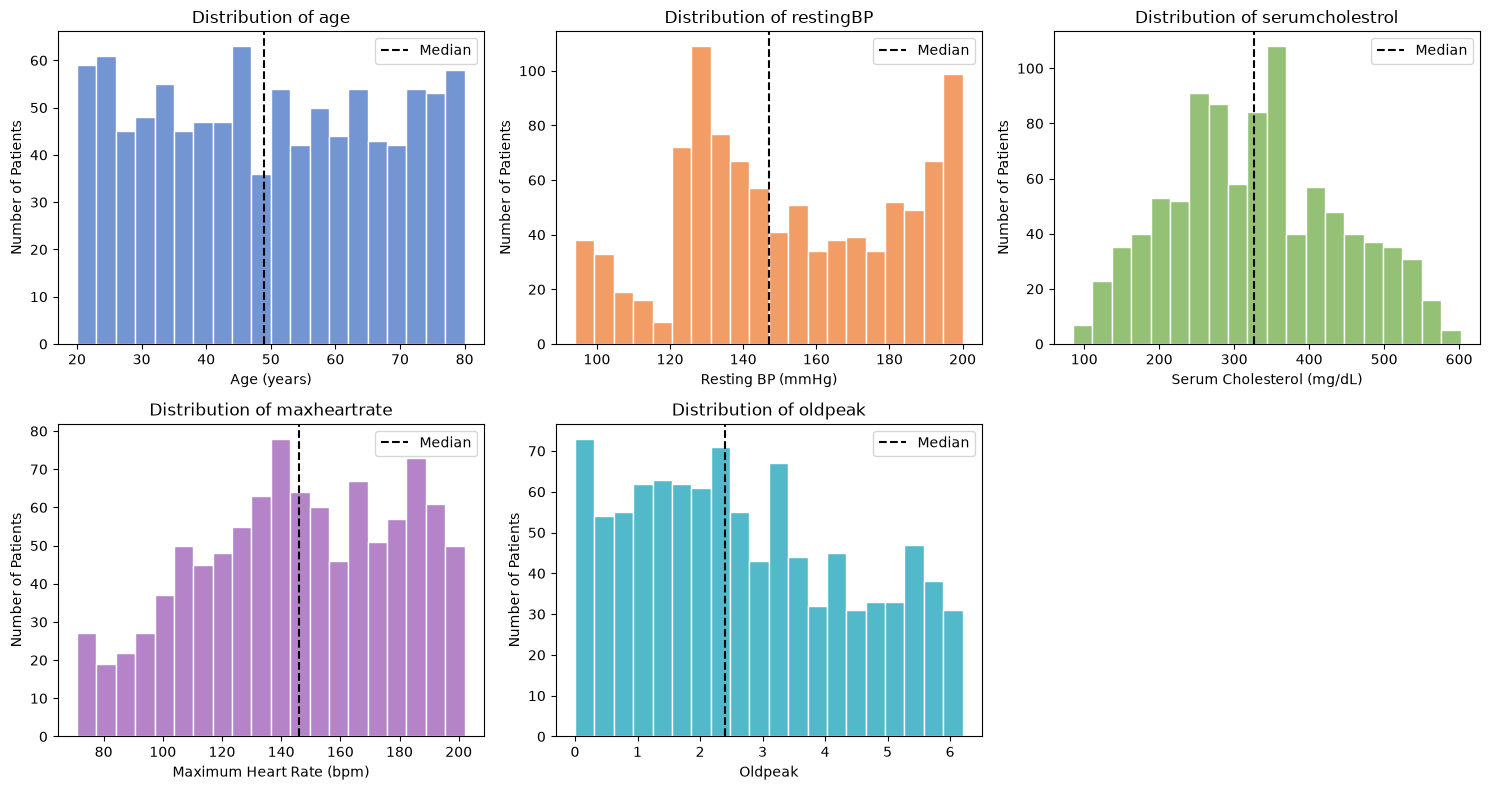

In [19]:
# Colors for each numerical feature
colors = ["#4472C4", "#ED7D31", "#70AD47",
          "#9B59B6", "#17A2B8"]

# Readable feature labels
labels = ["Age (years)", "Resting BP (mmHg)",
          "Serum Cholesterol (mg/dL)",
          "Maximum Heart Rate (bpm)", "Oldpeak"]

# Create histograms in a 2x3 layout
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(numerical):
    ax = axes.flat[i]

    # Plot histogram for each feature
    sns.histplot(
        cleaned[col].dropna(),
        bins=20,
        color=colors[i],
        edgecolor="white",
        ax=ax
    )

    # Add median reference line
    ax.axvline(
        cleaned[col].median(),
        color="black",
        linestyle="--",
        label="Median"
    )

    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(labels[i])
    ax.set_ylabel("Number of Patients")
    ax.legend()

# Remove the empty subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

Histograms were generated to examine the distribution and spread of the five numerical features. Median reference lines were included to highlight the center of each distribution. The cholesterol histogram excludes the 53 missing measurements, ensuring that invalid zero values do not distort the observed distribution.

## Outlier Detection

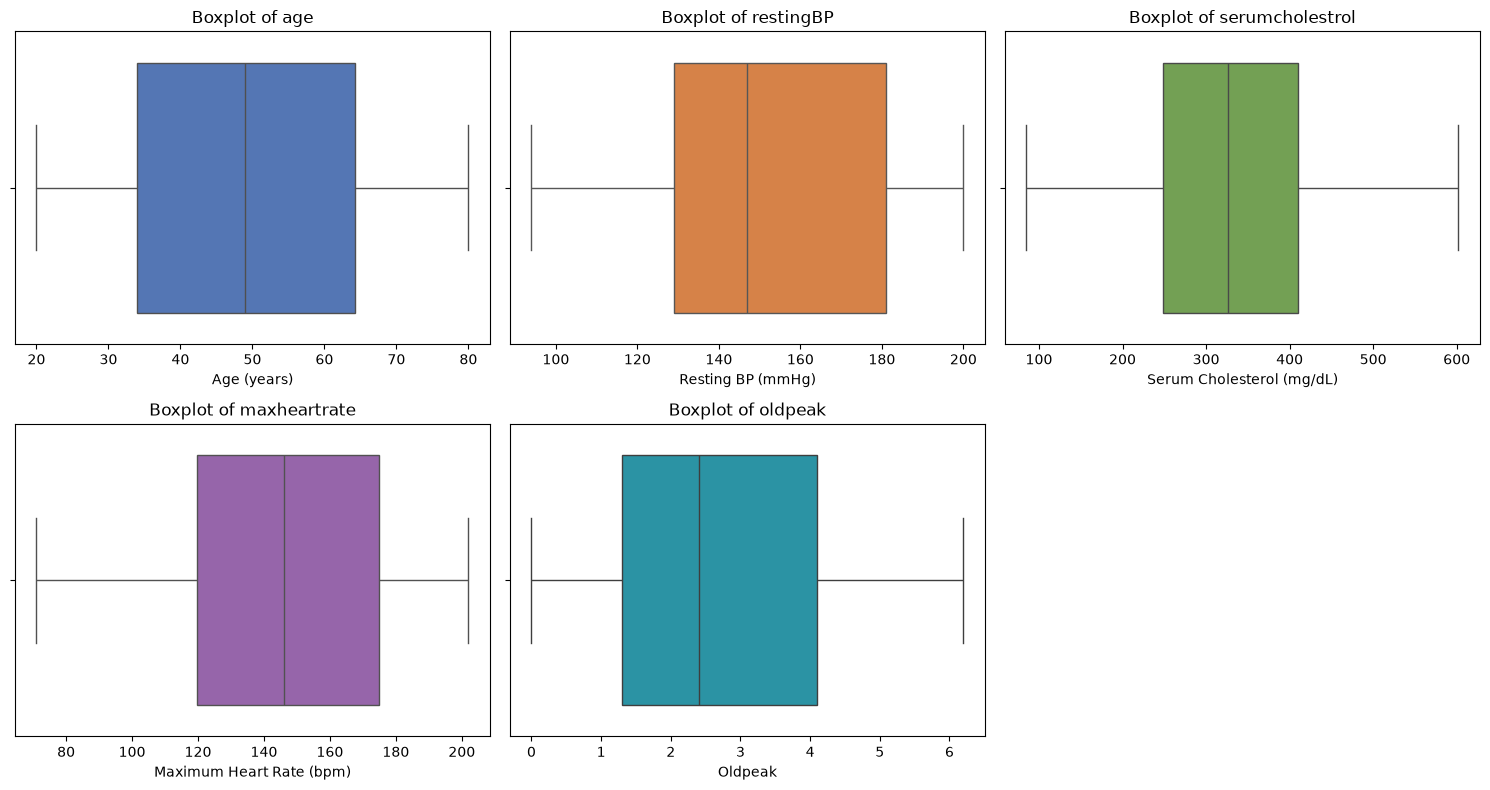

In [20]:
# Create boxplots for numerical features
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, col in enumerate(numerical):
    ax = axes.flat[i]

    # Create boxplot using the same feature color
    sns.boxplot(
        x=cleaned[col],
        color=colors[i],
        ax=ax
    )

    ax.set_title(f"Boxplot of {col}")
    ax.set_xlabel(labels[i])

# Remove the empty subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

In [21]:
# Store outlier counts for each feature
outlier_results = []

for col in numerical:

    # Calculate quartiles and IQR
    Q1 = cleaned[col].quantile(0.25)
    Q3 = cleaned[col].quantile(0.75)
    IQR = Q3 - Q1

    # Calculate lower and upper bounds
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # Count observations outside the bounds
    count = (
        (cleaned[col] < lower) |
        (cleaned[col] > upper)
    ).sum()

    outlier_results.append([col, count])

# Create and display results table
outlier_table = pd.DataFrame(
    outlier_results,
    columns=["Feature", "Outlier Count"]
)

display(
    outlier_table.style.hide(axis="index")
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#F2F2F2"),
            ("color", "black"), ("text-align", "left"),
            ("padding", "10px")
        ]},
        {"selector": "td", "props": [
            ("color", "black"), ("text-align", "left"),
            ("padding", "8px")
        ]}
    ])
)

Feature,Outlier Count
age,0
restingBP,0
serumcholestrol,0
maxheartrate,0
oldpeak,0


Boxplots and the 1.5 × IQR method were used to identify potential outliers across the numerical features. No statistical outliers were detected using this method. However, 12 cholesterol measurements remain outside the data dictionary's documented range. These values were retained because unusual clinical measurements do not necessarily indicate data errors.

## Categorical Feature Distributions

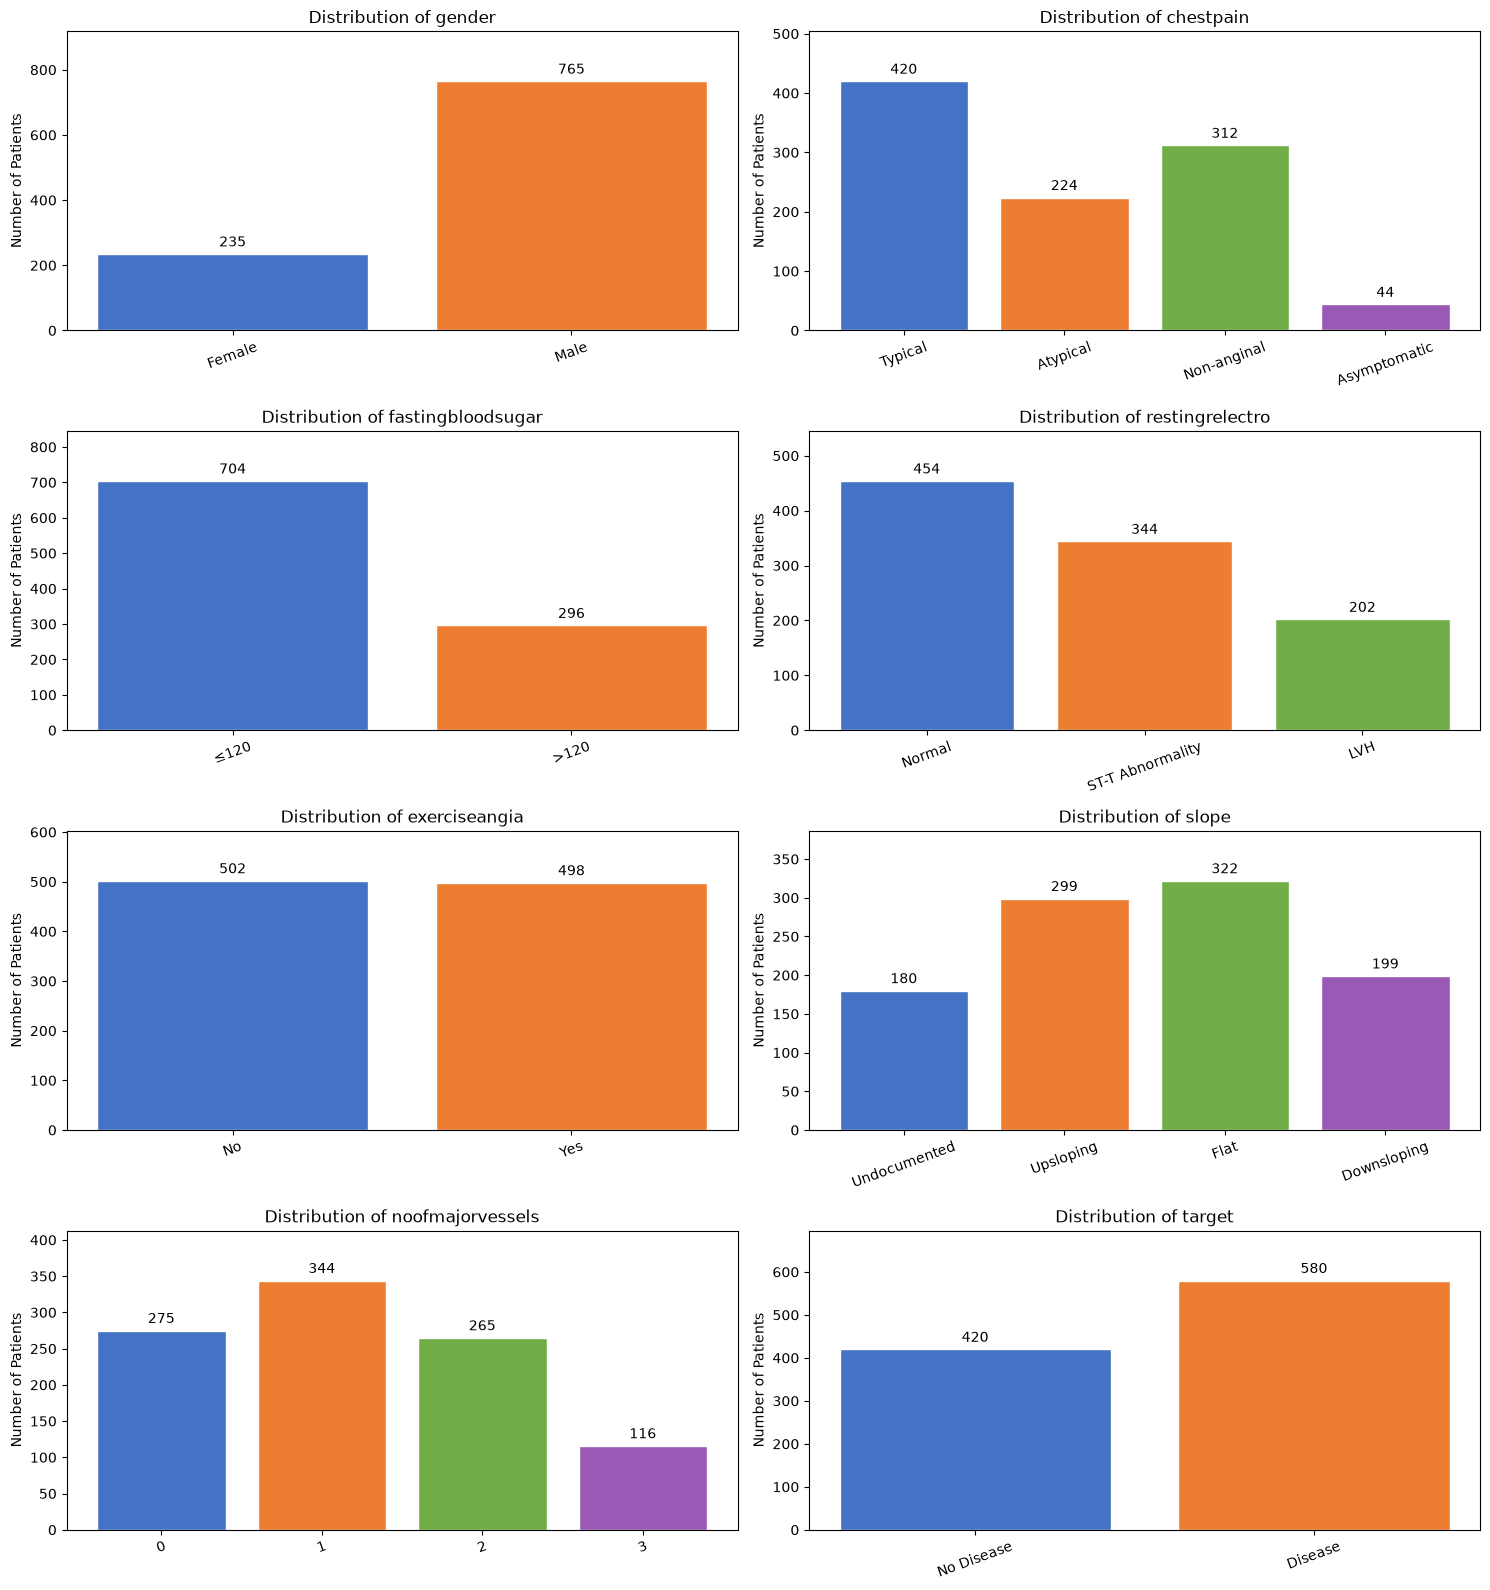

In [22]:
# Define readable labels for categorical features
category_labels = {
    "gender": {0: "Female", 1: "Male"},

    "chestpain": {
        0: "Typical", 1: "Atypical",
        2: "Non-anginal", 3: "Asymptomatic"
    },

    "fastingbloodsugar": {
        0: "≤120", 1: ">120"
    },

    "restingrelectro": {
        0: "Normal", 1: "ST-T Abnormality", 2: "LVH"
    },

    "exerciseangia": {0: "No", 1: "Yes"},

    "slope": {
        0: "Undocumented", 1: "Upsloping",
        2: "Flat", 3: "Downsloping"
    },

    "noofmajorvessels": {
        0: "0", 1: "1", 2: "2", 3: "3"
    },

    "target": {
        0: "No Disease", 1: "Disease"
    }
}

# Assign different colors to categories
bar_colors = ["#4472C4", "#ED7D31",
              "#70AD47", "#9B59B6"]

# Create a 4x2 grid of categorical plots
fig, axes = plt.subplots(4, 2, figsize=(15, 16))

for ax, (col, mapping) in zip(axes.flat, category_labels.items()):

    # Count each category in the original code order
    counts = cleaned[col].map(mapping).value_counts()
    counts = counts.reindex(list(mapping.values()), fill_value=0)

    # Plot category frequencies
    bars = ax.bar(
        counts.index,
        counts.values,
        color=bar_colors[:len(counts)],
        edgecolor="white"
    )

    # Add counts above each bar
    ax.bar_label(bars, padding=3)

    ax.set_title(f"Distribution of {col}")
    ax.set_ylabel("Number of Patients")
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, counts.max() * 1.2)

plt.tight_layout()
plt.show()

Categorical distributions were examined to understand the composition of the dataset. Male patients account for 76.5% of observations, and typical angina is the most frequently recorded chest pain type (42%). Exercise-induced angina is nearly evenly distributed, while the target variable contains 58% patients with heart disease and 42% without. The undocumented slope category accounts for 18% of records and requires further verification.

## Saving the Cleaned Dataset

In [24]:
from pathlib import Path

# Find the project folder using the original dataset location
project_dir = dataset_path.parent.parent.parent

# Set the correct output path
output_path = project_dir / "datasets" / "cleaned" / "cardiovascular_cleaned.csv"

# Make sure the folder exists
output_path.parent.mkdir(parents=True, exist_ok=True)

# Save the cleaned dataset
cleaned.to_csv(output_path, index=False)

# Verify the final dataset
print("Cleaned dataset saved successfully!")
print("Saved to:", output_path)
print("Final dataset shape:", cleaned.shape)
print("Total patients retained:", len(cleaned))
print("Missing cholesterol values:",
      cleaned["serumcholestrol"].isna().sum())

Cleaned dataset saved successfully!
Saved to: C:\Users\mmsr4\D37-Semantic-Data-Lake\datasets\cleaned\cardiovascular_cleaned.csv
Final dataset shape: (1000, 15)
Total patients retained: 1000
Missing cholesterol values: 53


## Age Group Distribution

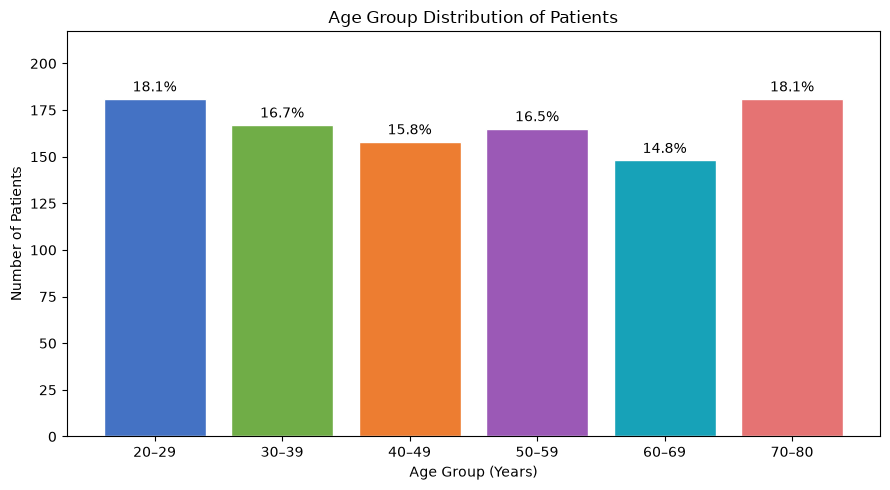

In [25]:
# Divide patients into age groups
age_groups = pd.cut(
    cleaned["age"],
    bins=[19, 29, 39, 49, 59, 69, 80],
    labels=["20–29", "30–39", "40–49",
            "50–59", "60–69", "70–80"]
)

# Count patients in each age group
age_counts = age_groups.value_counts().sort_index()

# Create a bar chart with distinct colors
plt.figure(figsize=(9, 5))

bars = plt.bar(
    age_counts.index,
    age_counts.values,
    color=["#4472C4", "#70AD47", "#ED7D31",
           "#9B59B6", "#17A2B8", "#E57373"],
    edgecolor="white"
)

# Display percentage above each bar
percentages = age_counts / len(cleaned) * 100
plt.bar_label(
    bars,
    labels=[f"{p:.1f}%" for p in percentages],
    padding=3
)

plt.title("Age Group Distribution of Patients")
plt.xlabel("Age Group (Years)")
plt.ylabel("Number of Patients")
plt.ylim(0, age_counts.max() * 1.2)

plt.tight_layout()
plt.show()

Patients are relatively evenly distributed across the six age groups, with the 20–29 and 70–80 age groups each representing 18.1% of the dataset. The 60–69 age group has the lowest representation at 14.8%. This suggests that the dataset includes patients across a broad age range without a strong concentration in any single age group.

## Missing Cholesterol Pattern

In [26]:
# Calculate cholesterol missingness within each target group
missing_summary = cleaned.groupby("target")[
    "cholesterol_missing"
].agg(["size", "sum"])

# Rename columns
missing_summary.columns = ["Total Patients", "Missing Cholesterol"]

# Calculate percentage missing within each group
missing_summary["Missing (%)"] = (
    missing_summary["Missing Cholesterol"] /
    missing_summary["Total Patients"] * 100
).round(2)

# Label the target groups
missing_summary.index = ["No Heart Disease", "Heart Disease"]

# Display formatted table
display(
    missing_summary.style
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#F2F2F2"),
            ("color", "black"), ("text-align", "left"),
            ("padding", "10px")
        ]},
        {"selector": "td", "props": [
            ("color", "black"), ("text-align", "left"),
            ("padding", "8px")
        ]}
    ])
)

,Total Patients,Missing Cholesterol,Missing (%)
No Heart Disease,420,0,0.000000
Heart Disease,580,53,9.140000


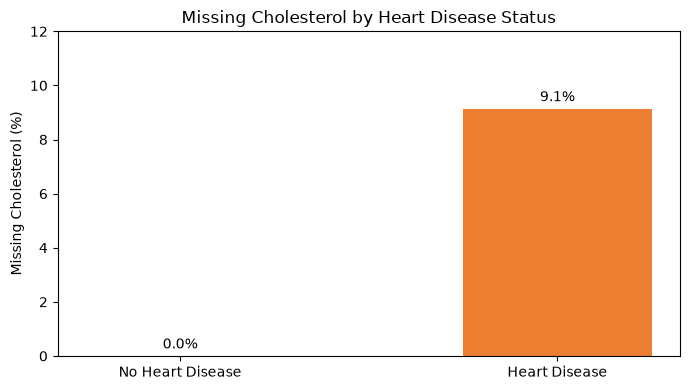

In [27]:
# Visualize cholesterol missingness by target group
plt.figure(figsize=(7, 4))

bars = plt.bar(
    missing_summary.index,
    missing_summary["Missing (%)"],
    color=["#4472C4", "#ED7D31"],
    width=0.5
)

# Add percentage labels
plt.bar_label(bars, fmt="%.1f%%", padding=3)

plt.title("Missing Cholesterol by Heart Disease Status")
plt.ylabel("Missing Cholesterol (%)")
plt.ylim(0, 12)

plt.tight_layout()
plt.show()

Missing cholesterol measurements were examined across the two heart disease classifications. All 53 missing cholesterol values belong to patients classified as having heart disease, representing 9.14% of that group. No cholesterol measurements are missing among patients without heart disease.

## Heart Disease Prevalence Across Categorical Features

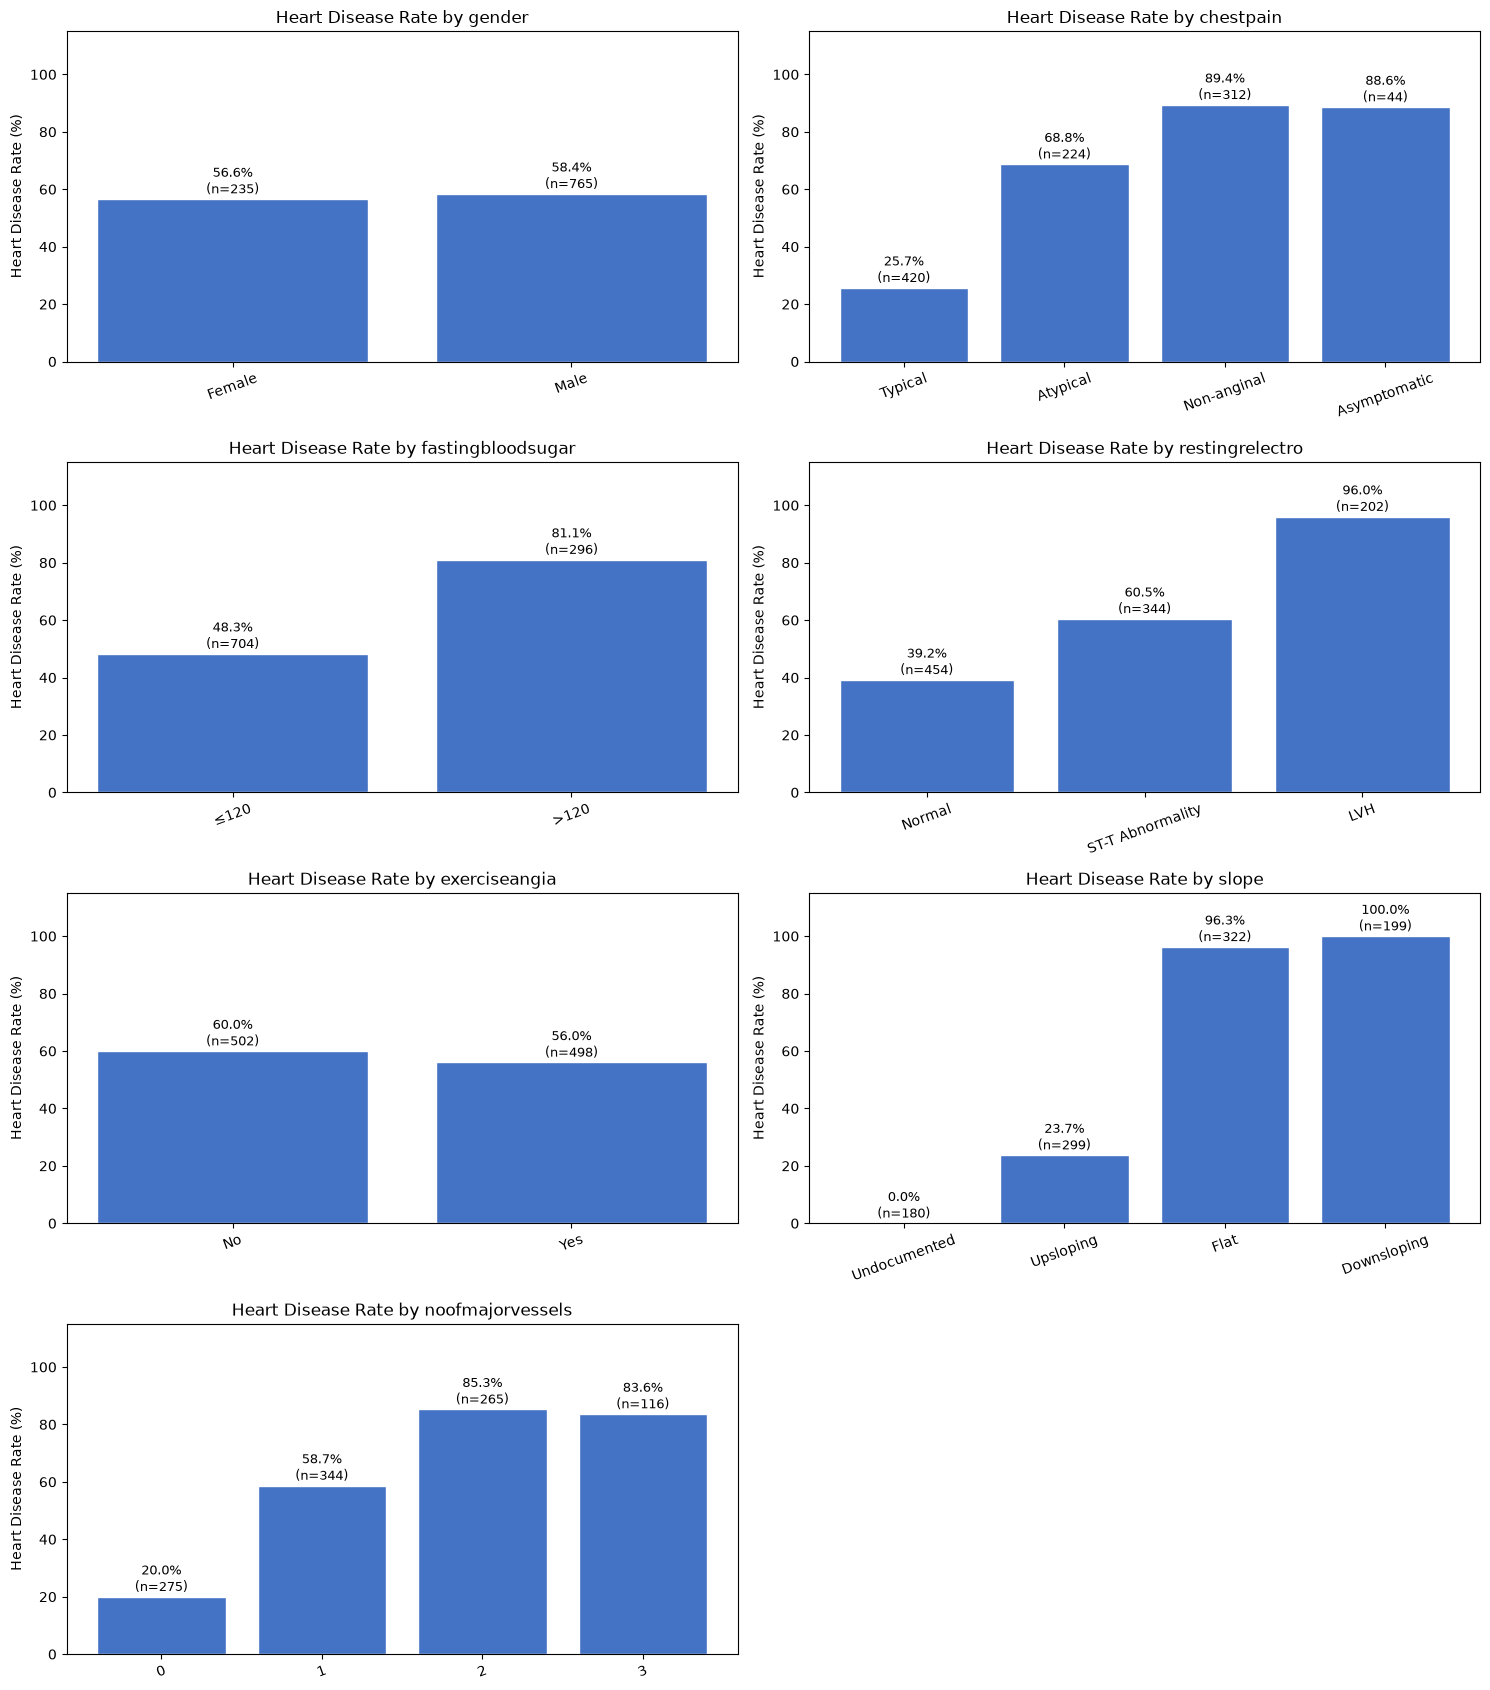

In [28]:

import matplotlib.pyplot as plt
# Compare heart disease prevalence across categorical features

features = [
    "gender", "chestpain", "fastingbloodsugar",
    "restingrelectro", "exerciseangia",
    "slope", "noofmajorvessels"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 17))

for ax, col in zip(axes.flat, features):

    # Calculate heart disease percentage within each category
    prevalence = (
        cleaned.groupby(col)["target"]
        .agg(["mean", "size"])
        .sort_index()
    )

    prevalence["Disease Rate (%)"] = prevalence["mean"] * 100

    # Use readable category labels from previous EDA
    labels = [
        category_labels[col].get(v, str(v))
        for v in prevalence.index
    ]

    bars = ax.bar(
        labels,
        prevalence["Disease Rate (%)"],
        color="#4472C4",
        edgecolor="white"
    )

    # Display prevalence and sample size above bars
    for bar, rate, n in zip(
        bars,
        prevalence["Disease Rate (%)"],
        prevalence["size"]
    ):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 2,
            f"{rate:.1f}%\n(n={n})",
            ha="center",
            fontsize=9
        )

    ax.set_title(f"Heart Disease Rate by {col}")
    ax.set_ylabel("Heart Disease Rate (%)")
    ax.set_ylim(0, 115)
    ax.tick_params(axis="x", rotation=20)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

Heart disease prevalence varies substantially across clinical features, while gender shows only a small difference (58.4% for males versus 56.6% for females). Non-anginal chest pain (89.4%), elevated fasting blood sugar (81.1%), and left ventricular hypertrophy (96.0%) are associated with higher disease prevalence. ST-segment slope shows particularly strong differences, with prevalence reaching 96.3% for flat and 100% for downsloping segments, compared to 23.7% for upsloping segments. Similarly, prevalence increases from 20.0% among patients with zero major vessels recorded to 85.3% among those with two. Overall, chest pain type, ECG findings, ST-segment slope, and major vessel count appear strongly associated with heart disease status, although the undocumented slope category warrants further investigation.

## Heart Disease Prevalence Across Age Groups

The relationship between patient age and heart disease prevalence was examined to identify potential differences in cardiovascular risk across age groups. Patients were divided into six age categories, and the percentage of individuals diagnosed with heart disease was calculated within each group. This analysis helps determine whether the proportion of heart disease cases varies with age and provides a clearer understanding of age-related patterns in the dataset.

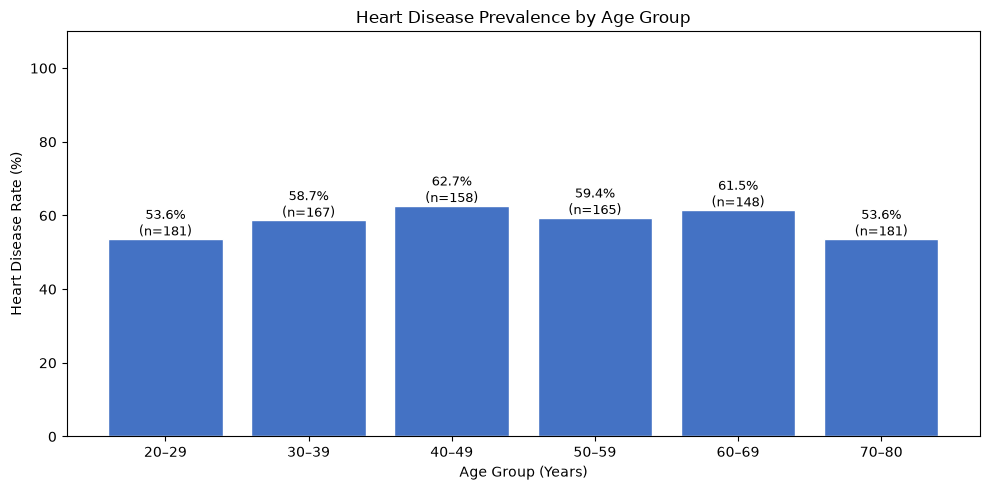

,mean,size,Disease Rate (%)
age_group,,,
20–29,0.54,181,53.59
30–39,0.59,167,58.68
40–49,0.63,158,62.66
50–59,0.59,165,59.39
60–69,0.61,148,61.49
70–80,0.54,181,53.59


In [29]:

# Calculate heart disease prevalence by age group
age_prevalence = (
    cleaned.assign(age_group=age_groups)
    .groupby("age_group", observed=False)["target"]
    .agg(["mean", "size"])
)

# Convert prevalence to percentages
age_prevalence["Disease Rate (%)"] = (
    age_prevalence["mean"] * 100
)

# Visualize heart disease prevalence by age group
plt.figure(figsize=(10, 5))

bars = plt.bar(
    age_prevalence.index.astype(str),
    age_prevalence["Disease Rate (%)"],
    color="#4472C4",
    edgecolor="white"
)

# Display prevalence and sample size
for bar, rate, n in zip(
    bars,
    age_prevalence["Disease Rate (%)"],
    age_prevalence["size"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%\n(n={n})",
        ha="center",
        fontsize=9
    )

plt.title("Heart Disease Prevalence by Age Group")
plt.xlabel("Age Group (Years)")
plt.ylabel("Heart Disease Rate (%)")
plt.ylim(0, 110)

plt.tight_layout()
plt.show()

# Display summary table
display(age_prevalence.round(2))


Heart disease rates are fairly similar across the different age groups, ranging from 53.6% to 62.7%. Patients aged 40–49 have the highest rate at 62.7%, followed by those aged 60–69 at 61.5%. Interestingly, both the youngest (20–29) and oldest (70–80) groups have the lowest rates at 53.6%. While there is a slight increase in heart disease prevalence through middle age, the rates don't consistently rise as patients get older. This suggests that age alone may not be a strong indicator of heart disease in this dataset.

## Numerical Features by Heart Disease Status

Numerical clinical measurements were compared between patients with and without heart disease to identify potential differences in their distributions. The analysis focuses on age, resting blood pressure, serum cholesterol, maximum heart rate, and ST-segment depression (oldpeak). Boxplots were used to compare the median, spread, and variability of each feature across the two patient groups. These comparisons help identify measurements that may be associated with heart disease status.

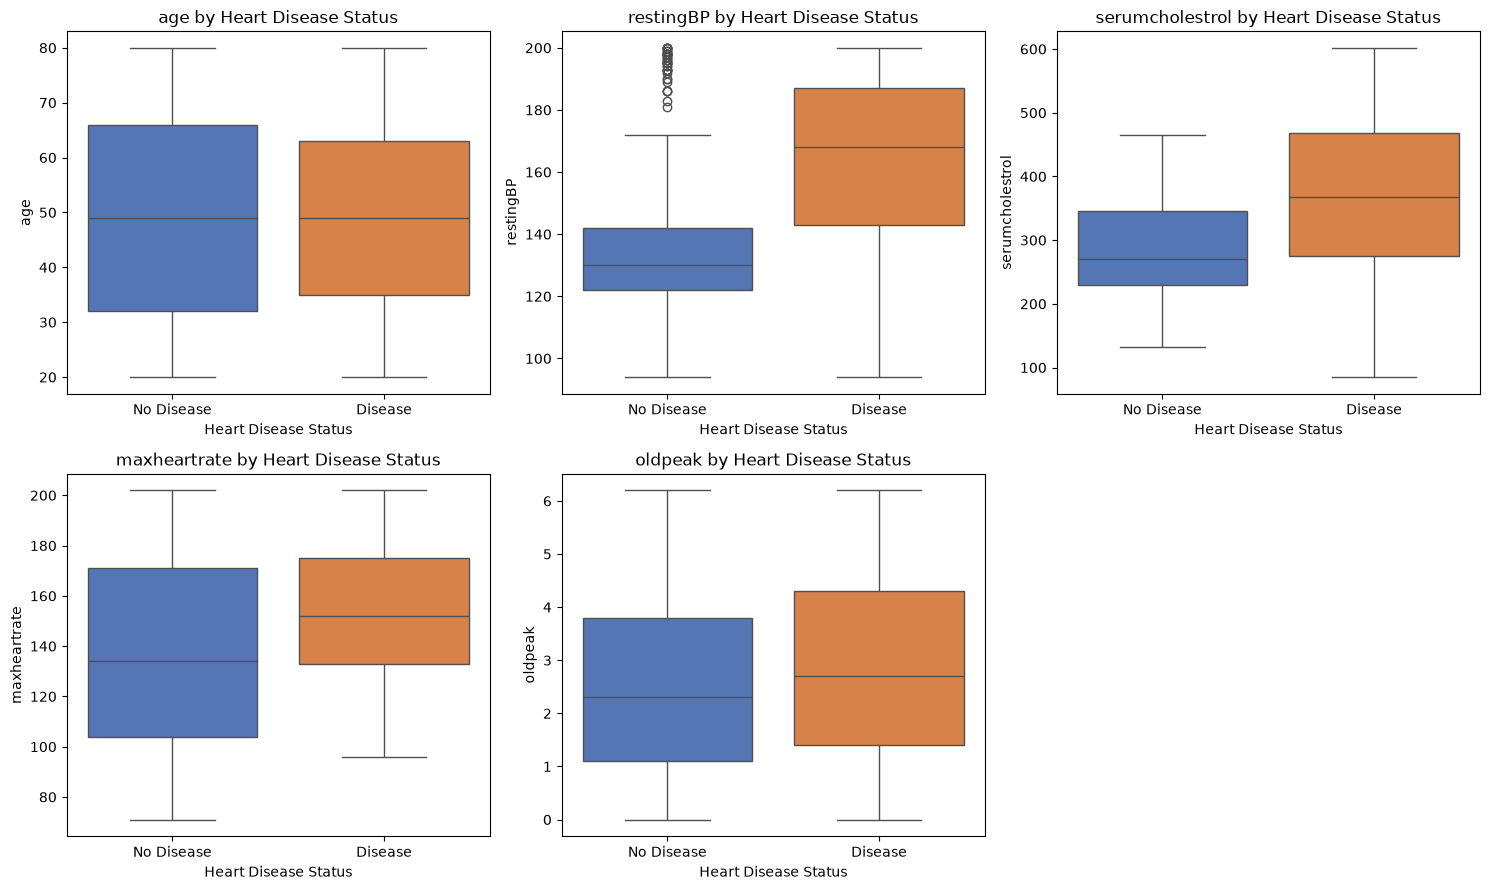

age               restingBP               serumcholestrol         \
         mean median    std      mean median    std            mean median   
target                                                                       
0       49.07   49.0  18.70    134.77  130.0  26.56          281.06  270.0   
1       49.37   49.0  17.25    164.04  168.0  26.04          366.99  368.0   

               maxheartrate               oldpeak               
           std         mean median    std    mean median   std  
target                                                          
0        87.56       136.31  134.0  39.26    2.51    2.3  1.72  
1       116.65       152.12  152.0  28.22    2.85    2.7  1.71

In [30]:

# Compare numerical features across target groups
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

# Use the numerical features defined earlier
for ax, col in zip(axes.flat, numerical):

    sns.boxplot(
        data=cleaned,
        x="target",
        y=col,
        hue="target",
        palette={0: "#4472C4", 1: "#ED7D31"},
        legend=False,
        ax=ax
    )

    ax.set_title(f"{col} by Heart Disease Status")
    ax.set_xlabel("Heart Disease Status")
    ax.set_ylabel(col)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No Disease", "Disease"])

# Hide unused subplot
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

# Compare summary statistics by target
numerical_comparison = (
    cleaned.groupby("target")[numerical]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(numerical_comparison)


The boxplots show some noticeable differences in clinical measurements between patients with and without heart disease. Patients with heart disease tend to have higher resting blood pressure, with a median of 168 compared to 130, and higher cholesterol levels, with a median of 368 compared to 270. Maximum heart rate is also higher in the heart disease group (152 vs. 134), while oldpeak shows a smaller difference (2.7 vs. 2.3). Interestingly, age distributions are almost identical between the two groups, with both having a median age of 49. Overall, resting blood pressure and cholesterol show the clearest differences, while age appears to have little relationship with heart disease status in this dataset.

## Correlation Analysis of Numerical Features

A correlation analysis was conducted to examine the strength and direction of linear relationships among numerical clinical features and heart disease status. Pearson correlation coefficients were calculated and visualized using a heatmap, with values ranging from -1 to 1. Positive values indicate that two variables tend to increase together, while negative values indicate an inverse relationship. This analysis helps identify potentially informative features and relationships that may be useful for further statistical analysis or predictive modeling.

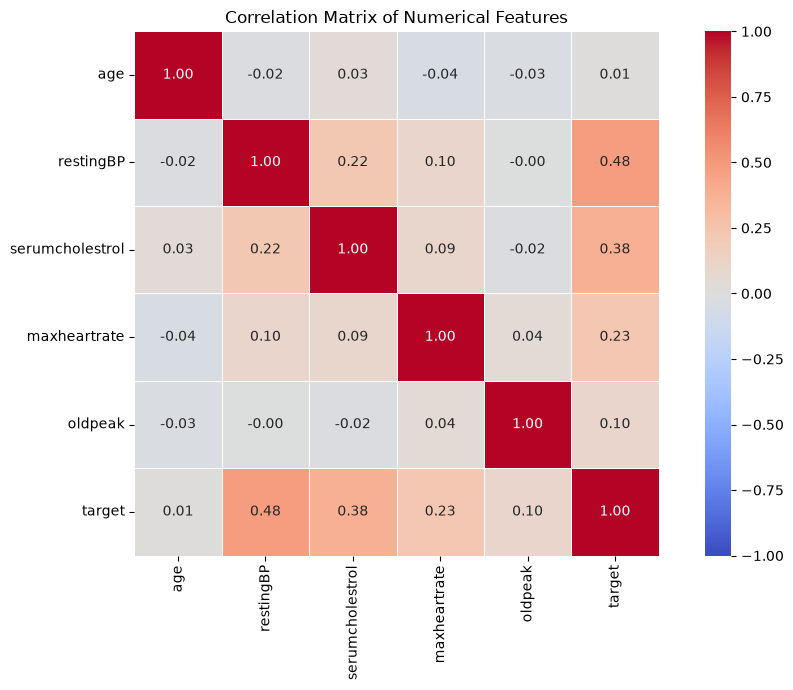

Correlation with Heart Disease:


,Pearson Correlation
restingBP,0.482
serumcholestrol,0.378
maxheartrate,0.228
oldpeak,0.098
age,0.008


In [31]:

# Select numerical variables and heart disease target
corr_features = numerical + ["target"]

# Calculate Pearson correlation matrix
correlation_matrix = cleaned[corr_features].corr()

# Create correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

# Examine correlation with heart disease
target_correlation = (
    correlation_matrix["target"]
    .drop("target")
    .sort_values(ascending=False)
)

print("Correlation with Heart Disease:")
display(target_correlation.to_frame(
    name="Pearson Correlation"
).round(3))


The correlation matrix shows that resting blood pressure has the strongest positive correlation with heart disease (0.48), followed by serum cholesterol (0.38) and maximum heart rate (0.23). Oldpeak has a much weaker correlation (0.10), while age has almost no correlation with heart disease (0.01). This matches what we saw in the earlier boxplots, where blood pressure and cholesterol showed the biggest differences between patients with and without heart disease. Most of the numerical features also have relatively weak correlations with each other, suggesting they capture different aspects of patient health. Overall, resting blood pressure and cholesterol appear to be the most strongly associated numerical features in this dataset, although correlation alone does not imply causation.

## Gender and Age Interactions with Heart Disease

Heart disease prevalence was further analyzed across age groups and gender to explore whether the observed age-related patterns differ between male and female patients. The proportion of patients diagnosed with heart disease was calculated for each age and gender combination. Grouped bar charts were used to compare prevalence rates, allowing differences between demographic groups to be examined while accounting for the size of each subgroup.

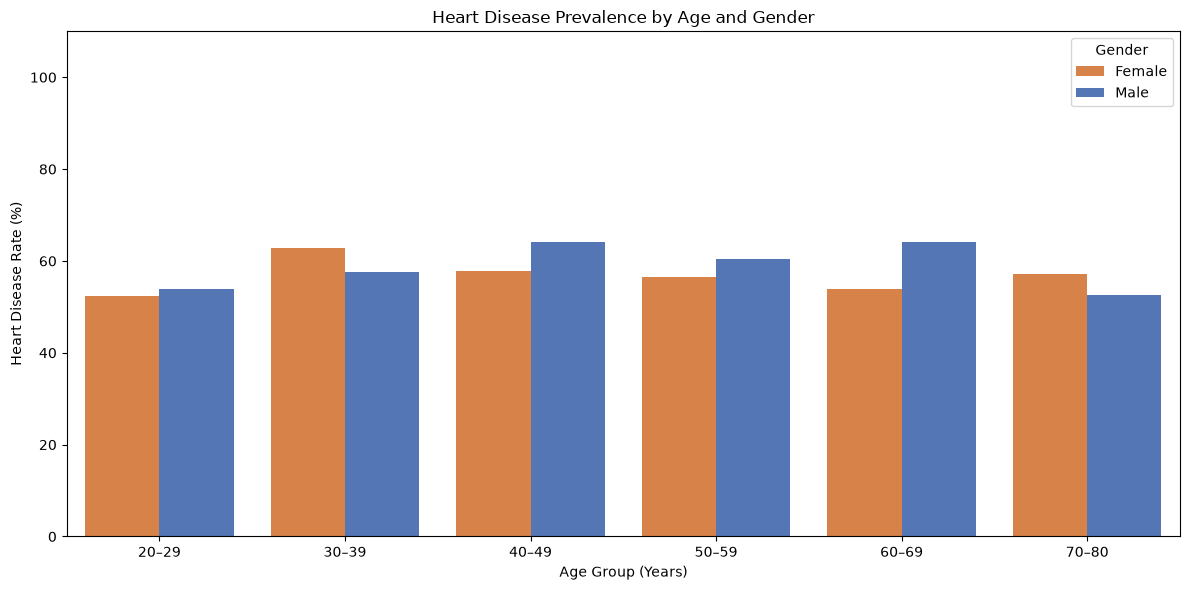

,age_group,Gender,size,Disease Rate (%)
0,20–29,Female,42,52.38
1,20–29,Male,139,53.96
2,30–39,Female,35,62.86
3,30–39,Male,132,57.58
4,40–49,Female,38,57.89
5,40–49,Male,120,64.17
6,50–59,Female,39,56.41
7,50–59,Male,126,60.32
8,60–69,Female,39,53.85
9,60–69,Male,109,64.22


In [32]:

# Create age groups and readable gender labels
demographic_data = cleaned.copy()

demographic_data["age_group"] = age_groups
demographic_data["Gender"] = (
    demographic_data["gender"].map({
        0: "Female",
        1: "Male"
    })
)

# Calculate disease prevalence by age and gender
gender_age_summary = (
    demographic_data
    .groupby(["age_group", "Gender"], observed=False)["target"]
    .agg(["mean", "size"])
    .reset_index()
)

gender_age_summary["Disease Rate (%)"] = (
    gender_age_summary["mean"] * 100
)

# Plot prevalence across demographic groups
plt.figure(figsize=(12, 6))

sns.barplot(
    data=gender_age_summary,
    x="age_group",
    y="Disease Rate (%)",
    hue="Gender",
    palette=["#ED7D31", "#4472C4"]
)

plt.title("Heart Disease Prevalence by Age and Gender")
plt.xlabel("Age Group (Years)")
plt.ylabel("Heart Disease Rate (%)")
plt.ylim(0, 110)
plt.legend(title="Gender")

plt.tight_layout()
plt.show()

# Display subgroup sample sizes and rates
display(
    gender_age_summary[
        ["age_group", "Gender",
         "size", "Disease Rate (%)"]
    ].round(2)
)


Heart disease rates vary slightly between males and females across age groups, but there isn't a consistent pattern where one gender always has a higher rate. Males have higher prevalence in the 40–49, 50–59, and 60–69 age groups, with the largest difference appearing at ages 60–69 (64.2% for males compared to 53.9% for females). On the other hand, females have higher rates in the 30–39 and 70–80 age groups. Interestingly, the youngest age group has almost identical rates for both genders, around 53%. Overall, the differences seem to depend on the age group rather than gender alone, although the smaller female sample sizes should be considered when interpreting these results.

## Chest Pain and Exercise-Induced Angina

Chest pain type and exercise-induced angina were examined together to investigate their relationship with heart disease prevalence. Since both features describe symptoms potentially associated with cardiovascular conditions, analyzing their combined distributions may reveal patterns that are not apparent when examining each feature independently. A heatmap was used to compare the percentage of heart disease cases across different symptom combinations, while sample counts were included to provide context for the observed prevalence rates.

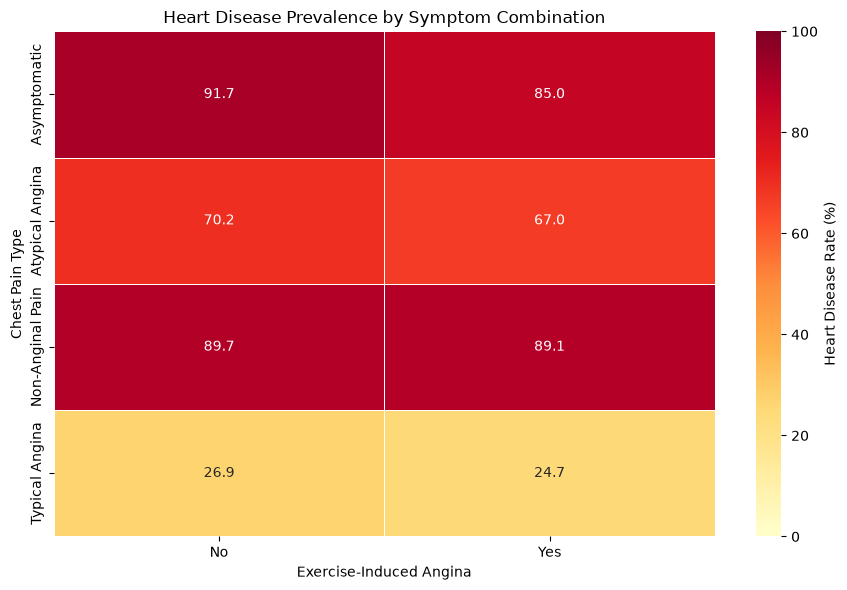

,Chest Pain Type,Exercise Angina,size,Disease Rate (%)
0,Typical Angina,No,201,26.87
1,Typical Angina,Yes,219,24.66
2,Atypical Angina,No,121,70.25
3,Atypical Angina,Yes,103,66.99
4,Non-Anginal Pain,No,156,89.74
5,Non-Anginal Pain,Yes,156,89.10
6,Asymptomatic,No,24,91.67
7,Asymptomatic,Yes,20,85.00


In [33]:

# Calculate heart disease prevalence by symptom combination
symptom_summary = (
    cleaned.groupby(
        ["chestpain", "exerciseangia"]
    )["target"]
    .agg(["mean", "size"])
    .reset_index()
)

# Convert mean to disease prevalence percentage
symptom_summary["Disease Rate (%)"] = (
    symptom_summary["mean"] * 100
)

# Create readable labels
symptom_summary["Chest Pain Type"] = (
    symptom_summary["chestpain"].map({
        0: "Typical Angina",
        1: "Atypical Angina",
        2: "Non-Anginal Pain",
        3: "Asymptomatic"
    })
)

symptom_summary["Exercise Angina"] = (
    symptom_summary["exerciseangia"].map({
        0: "No",
        1: "Yes"
    })
)

# Create prevalence pivot table
symptom_pivot = symptom_summary.pivot(
    index="Chest Pain Type",
    columns="Exercise Angina",
    values="Disease Rate (%)"
)

# Plot prevalence heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    symptom_pivot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Heart Disease Rate (%)"}
)

plt.title("Heart Disease Prevalence by Symptom Combination")
plt.xlabel("Exercise-Induced Angina")
plt.ylabel("Chest Pain Type")

plt.tight_layout()
plt.show()

# Display counts and prevalence rates
display(
    symptom_summary[
        ["Chest Pain Type", "Exercise Angina",
         "size", "Disease Rate (%)"]
    ].round(2)
)


Chest pain type seems to have a much stronger relationship with heart disease than exercise-induced angina. Patients with non-anginal pain have consistently high heart disease rates of around 89%, regardless of whether they experience exercise-induced angina. Asymptomatic patients also have high rates, reaching 91.7% among those without exercise-induced angina, although this group has a smaller sample size. In comparison, patients with typical angina have much lower rates, around 25–27%. Interestingly, within every chest pain category, patients without exercise-induced angina have slightly higher heart disease rates than those with it. Overall, chest pain type appears to be a more useful indicator of heart disease in this dataset than exercise-induced angina alone.

## Maximum Heart Rate and Heart Disease

Maximum heart rate achieved during exercise was analyzed to examine its relationship with heart disease status. The distribution of maximum heart rate was compared between patients with and without heart disease using overlapping histograms and density curves. This analysis helps identify whether patients diagnosed with heart disease tend to exhibit different exercise-related heart rate patterns and provides additional insight into cardiovascular performance across the two groups.

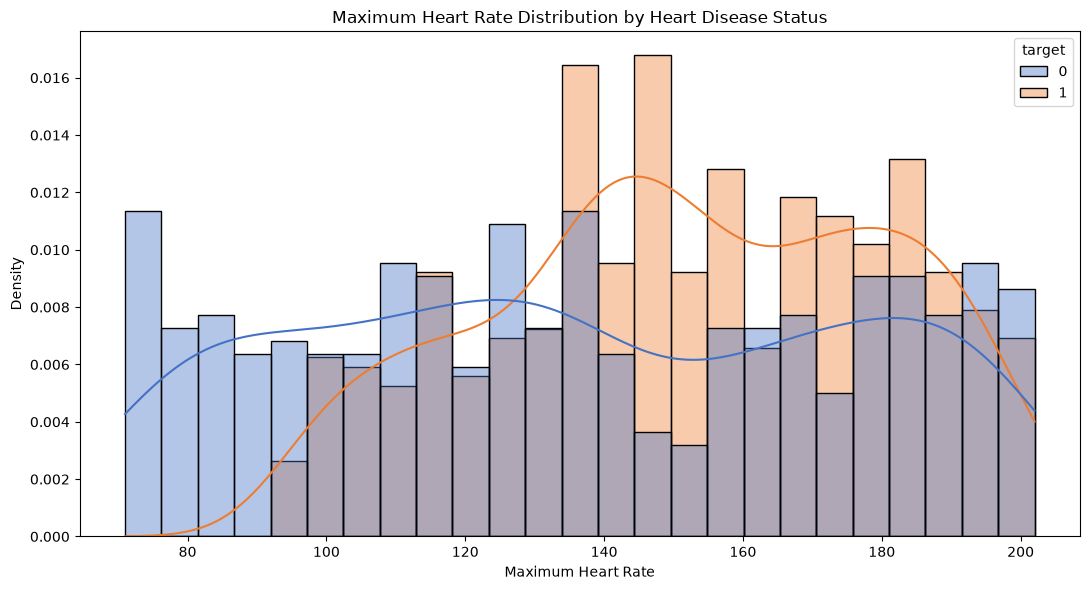

,count,mean,median,std,min,max
No Heart Disease,420,136.31,134.0,39.26,71,202
Heart Disease,580,152.12,152.0,28.22,96,202


In [34]:

# Compare maximum heart rate distributions by heart disease status
plt.figure(figsize=(11, 6))

sns.histplot(
    data=cleaned,
    x="maxheartrate",
    hue="target",
    bins=25,
    kde=True,
    stat="density",
    common_norm=False,
    palette={0: "#4472C4", 1: "#ED7D31"},
    alpha=0.4
)

plt.title("Maximum Heart Rate Distribution by Heart Disease Status")
plt.xlabel("Maximum Heart Rate")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

# Calculate summary statistics for each group
heart_rate_summary = (
    cleaned.groupby("target")["maxheartrate"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

heart_rate_summary.index = [
    "No Heart Disease",
    "Heart Disease"
]

display(heart_rate_summary)


Patients with heart disease tend to have higher maximum heart rates, with an average of 152.1 compared to 136.3 for patients without heart disease. The distributions also look slightly different, with the heart disease group more concentrated around 135–160 bpm, while patients without heart disease have a wider spread of values. This is also reflected in the standard deviations (28.2 vs. 39.3), showing greater variability among patients without heart disease. Although the two distributions overlap quite a bit, higher maximum heart rates appear to be moderately associated with heart disease in this dataset.

## ST Depression and Exercise-Induced Angina

ST-segment depression (oldpeak) was examined alongside exercise-induced angina to explore their combined relationship with heart disease status. ST depression is a clinical measurement recorded during exercise testing, while exercise-induced angina indicates whether a patient experiences angina during physical exertion. Comparing the distribution of oldpeak across these categories may reveal differences in exercise-related cardiovascular responses between patients with and without heart disease.

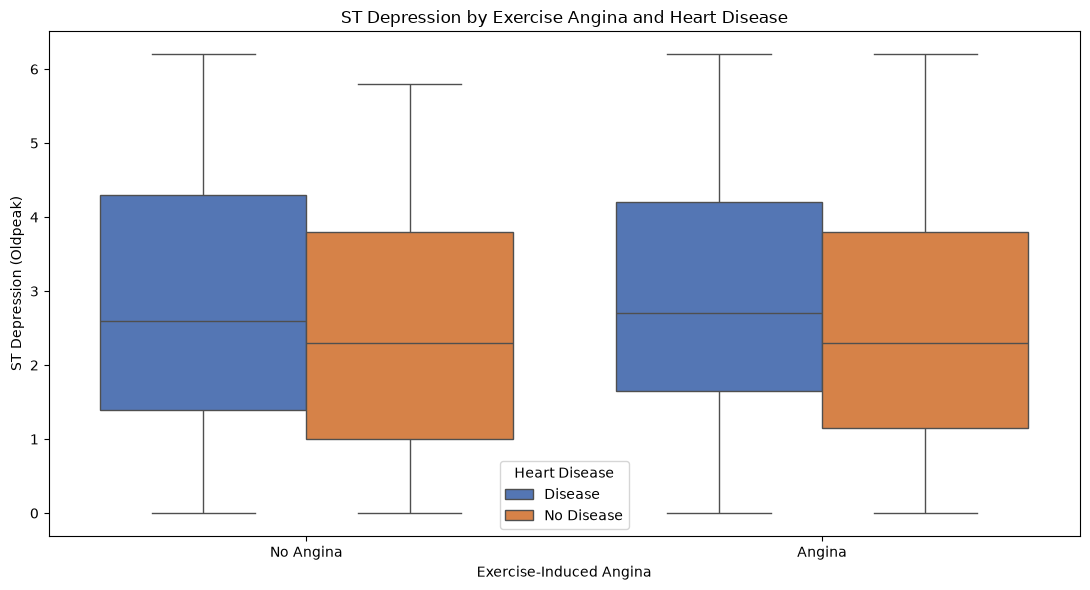

count  mean  median   std
Exercise Angina Heart Disease                           
Angina          Disease          279  2.85     2.7  1.70
                No Disease       219  2.51     2.3  1.68
No Angina       Disease          301  2.85     2.6  1.72
                No Disease       201  2.51     2.3  1.76

In [35]:

# Create readable labels for plotting
exercise_data = cleaned.copy()

exercise_data["Heart Disease"] = (
    exercise_data["target"].map({
        0: "No Disease",
        1: "Disease"
    })
)

exercise_data["Exercise Angina"] = (
    exercise_data["exerciseangia"].map({
        0: "No Angina",
        1: "Angina"
    })
)

# Compare oldpeak across exercise angina groups
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=exercise_data,
    x="Exercise Angina",
    y="oldpeak",
    hue="Heart Disease",
    palette=["#4472C4", "#ED7D31"]
)

plt.title("ST Depression by Exercise Angina and Heart Disease")
plt.xlabel("Exercise-Induced Angina")
plt.ylabel("ST Depression (Oldpeak)")
plt.legend(title="Heart Disease")

plt.tight_layout()
plt.show()

# Summary statistics across groups
oldpeak_summary = (
    exercise_data.groupby(
        ["Exercise Angina", "Heart Disease"]
    )["oldpeak"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(oldpeak_summary)


ST depression (oldpeak) is slightly higher among patients with heart disease, with an average of 2.85 compared to 2.51 for those without heart disease. This pattern stays pretty consistent regardless of whether patients experience exercise-induced angina. For patients with angina, the median oldpeak is 2.7 for those with heart disease versus 2.3 for those without, while the difference is similar for patients without angina (2.6 vs. 2.3). Interestingly, the distributions overlap quite a bit across all four groups, suggesting that oldpeak alone may not clearly distinguish patients with heart disease. Overall, exercise-induced angina doesn't appear to make much of a difference in the relationship between oldpeak and heart disease in this dataset.

## Number of Major Vessels and Heart Disease Prevalence

The number of major vessels was examined to investigate its association with heart disease prevalence. Patients were grouped according to the recorded number of major vessels, and the percentage diagnosed with heart disease was calculated for each category. A bar chart was used to compare prevalence rates, while sample sizes were included to provide context for the observed differences. This analysis helps identify whether the recorded vessel categories are associated with changes in heart disease prevalence.

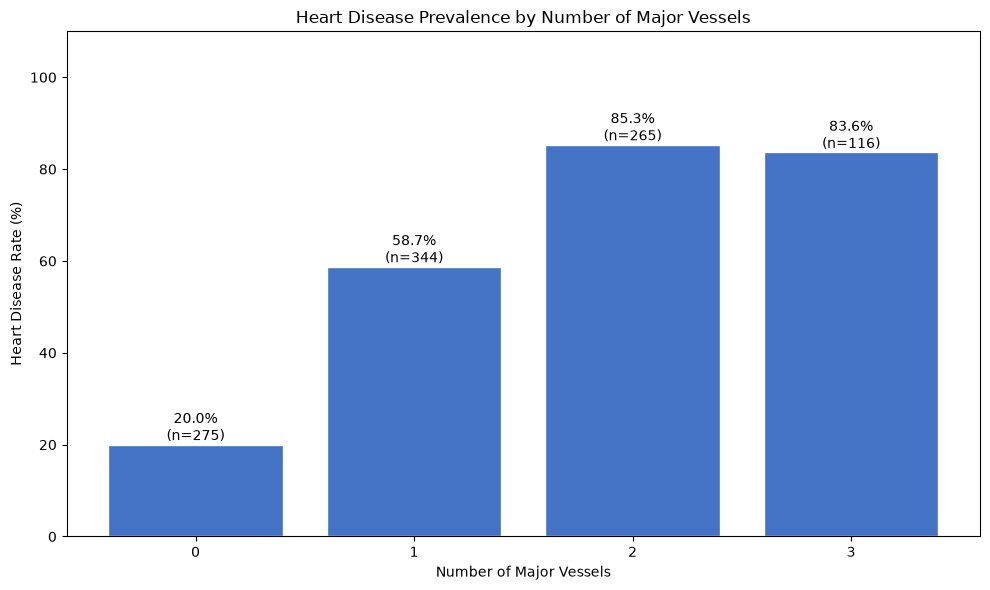

,mean,size,Disease Rate (%)
noofmajorvessels,,,
0,0.20,275,20.00
1,0.59,344,58.72
2,0.85,265,85.28
3,0.84,116,83.62


In [36]:

# Calculate heart disease prevalence by number of major vessels
vessel_summary = (
    cleaned.groupby("noofmajorvessels")["target"]
    .agg(["mean", "size"])
    .sort_index()
)

# Convert disease prevalence to percentages
vessel_summary["Disease Rate (%)"] = (
    vessel_summary["mean"] * 100
)

# Visualize disease prevalence across vessel categories
plt.figure(figsize=(10, 6))

bars = plt.bar(
    vessel_summary.index.astype(str),
    vessel_summary["Disease Rate (%)"],
    color="#4472C4",
    edgecolor="white"
)

# Display prevalence and sample sizes
for bar, rate, n in zip(
    bars,
    vessel_summary["Disease Rate (%)"],
    vessel_summary["size"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%\n(n={n})",
        ha="center",
        fontsize=10
    )

plt.title("Heart Disease Prevalence by Number of Major Vessels")
plt.xlabel("Number of Major Vessels")
plt.ylabel("Heart Disease Rate (%)")
plt.ylim(0, 110)

plt.tight_layout()
plt.show()

# Display numerical summary
display(vessel_summary.round(2))


Heart disease prevalence increases quite a bit as the number of major vessels goes up. Patients with zero major vessels recorded have the lowest disease rate at 20.0%, while those with one vessel have a much higher rate of 58.7%. The rate increases further to 85.3% for patients with two vessels, before dropping slightly to 83.6% for those with three. Interestingly, the difference between two and three vessels is fairly small compared to the earlier increases. Overall, the number of major vessels appears to have a strong relationship with heart disease in this dataset, with patients in the higher vessel categories showing much higher disease prevalence.

## EDA Summary and Key Findings

### Dataset Overview
- The dataset contains **1,000 patient records**, with 580 patients (58%) diagnosed with heart disease and 420 (42%) without.
- During cleaning, we found **53 cholesterol values recorded as zero**, which were treated as missing values.
- We also found **180 records with an undocumented slope category**, which may need to be looked into further.

### Age and Gender
- Heart disease rates were pretty similar across age groups, ranging from 53.6% to 62.7%. The highest rate was among patients aged 40–49.
- Males had a slightly higher heart disease rate (58.4%) than females (56.6%), but the difference wasn't very large.
- From these results, age and gender don't seem to separate patients with and without heart disease as clearly as some of the clinical measurements do.

### Numerical Features
The correlation analysis showed that some measurements had a clearer relationship with heart disease than others.

| Feature | Correlation | What We Found |
|---|---|---|
| Resting Blood Pressure | 0.48 | Patients with heart disease generally had higher blood pressure. |
| Serum Cholesterol | 0.38 | Cholesterol levels were noticeably higher in patients with heart disease. |
| Maximum Heart Rate | 0.23 | Patients with heart disease had a higher average maximum heart rate. |
| Oldpeak | 0.10 | There was a small difference between the two groups, but their distributions overlapped quite a bit. |
| Age | 0.01 | There was almost no linear relationship with heart disease. |

### Categorical Features
A few categorical features stood out when comparing heart disease rates:

- **Chest pain:** Patients with non-anginal pain had a heart disease rate of 89.4%, compared to just 25.7% for those with typical angina.
- **Resting ECG:** Patients with left ventricular hypertrophy had a much higher disease rate (96.0%) than those with normal ECG results (39.2%).
- **ST-segment slope:** Flat and downsloping segments had particularly high heart disease rates of 96.3% and 100%, respectively.
- **Number of major vessels:** Disease rates increased from 20.0% for patients with zero vessels recorded to 85.3% for those with two.
- **Exercise-induced angina:** There wasn't much difference between patients who experienced exercise-induced angina (56.0%) and those who didn't (60.0%).

### What Stood Out
- The biggest differences in heart disease rates came from clinical features rather than age or gender.
- Resting blood pressure and cholesterol had the highest correlations with heart disease among the numerical variables.
- Chest pain type, ST-segment slope, resting ECG results, and major vessel count also showed noticeable differences between patient groups.
- Some results were unexpected, especially the higher maximum heart rates among patients with heart disease and the relatively small differences in exercise-induced angina.

### What Could Be Explored Next
- Look more closely at the undocumented slope values to understand why they appear in the dataset.
- Decide how to handle the missing cholesterol measurements before building a model.
- Use the features that stood out during EDA to explore which ones are most useful for predicting heart disease.
- Test a classification model to see whether the patterns found in this analysis hold up on new data.

Overall, this EDA gave us a better idea of which patient characteristics are most closely related to heart disease in the dataset. While several clinical features showed clear differences, these patterns don't necessarily mean that one factor causes heart disease. They do, however, give us a good starting point for the next stage of analysis.